# 🖼️ What is a Picture (for a Computer)?
## Copyright notice
HSLU DFK | Colabor: Zoom In Zoom Out | 2026 Thomas Knüsel, [MIT License](LICENSE). 
Feel free to modify and reuse the content. 

---
## Pixels, Channels & the RGB Model

---

A digital image is just a **grid of numbers**. Each cell in the grid is a **pixel** (picture element), and each pixel stores its color as a combination of three (or four) numbers:

| Channel | Meaning | Range |
|---------|---------|-------|
| **R** — Red   | How much red light | 0–255 |
| **G** — Green | How much green light | 0–255 |
| **B** — Blue  | How much blue light | 0–255 |
| **A** — Alpha | Transparency (optional) | 0–255 |

Each value is **8 bits** = 2⁸ = **256 possible values** (0–255).  
Three channels × 8 bits = **24-bit color** → over **16 million** possible colors per pixel.

```
Image shape:  (height, width, channels)
              e.g. (480, 640, 3)  →  640×480 pixels, 3 color channels
```

> **Tip:** In NumPy/PIL the array axes are always `[row, col, channel]` — i.e. `[y, x, c]`.
>
> 

## 0 — Install & imports 

In [16]:
pip install pillow numpy matplotlib tqdm ipywidgets

Note: you may need to restart the kernel to use updated packages.


## 0 — Load Libraries

In [17]:
import sys
!{sys.executable} -m pip install ipympl
    
%matplotlib widget

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from PIL import Image
import ipywidgets as widgets
from IPython.display import display, clear_output
import io

plt.rcParams['figure.dpi'] = 110
plt.rcParams['axes.titlesize'] = 11
plt.rcParams['axes.titlepad'] = 8
print('✓ Libraries loaded')

import datetime

save_btn = widgets.Button(description='💾 Save snapshot', button_style='info',
                          layout=widgets.Layout(width='160px'))

def on_save(b):
    ts = datetime.datetime.now().strftime('%H%M%S')
    path = f'pixel_grid_{ts}.png'
    fig.savefig(path, dpi=150, bbox_inches='tight', facecolor=fig.get_facecolor())
    print(f'✓ Saved → {path}')

save_btn.on_click(on_save)

✓ Libraries loaded


---
## 1 — Upload your image

Run the cell below, click **Upload**, and choose any image from your computer - preferably a colorful Picture...


Troubleshooting: If this is not working you might need to hard Reload the Page (**"Cmd + Shift + R"**).

In [18]:
uploader = widgets.FileUpload(accept='image/*', multiple=False, description='Upload image')
display(uploader)

FileUpload(value=(), accept='image/*', description='Upload image')

---
## 2 — Load & inspect the image array

After uploading, run this cell to convert it into a NumPy array and peek at its structure.

In [19]:
# --- load from uploader (ipywidgets 8.x compatible) ---
if not uploader.value:
    raise ValueError('Please upload an image first (cell above).')

file_info = uploader.value[0]  # tuple, not dict
img_pil = Image.open(io.BytesIO(file_info['content']))

# Ensure RGBA so alpha is always present
img_rgba = img_pil.convert('RGBA')
img_rgb  = img_pil.convert('RGB')

arr  = np.array(img_rgba)
arr3 = np.array(img_rgb)

H, W = arr.shape[:2]

print(f'Filename   : {file_info["name"]}')          # was file_info['metadata']['name']
print(f'Original   : {img_pil.size[0]} × {img_pil.size[1]} px  |  mode: {img_pil.mode}')
print(f'Array shape: {arr.shape}  → (height, width, channels)')
print(f'Dtype      : {arr.dtype}')
print(f'Total pixels: {H * W:,}')

py, px = H // 2, W // 2
r, g, b, a = arr[py, px]
print(f'\nCentre pixel [{py}, {px}]:')
print(f'  R = {r}  G = {g}  B = {b}  A = {a}')
print(f'  Hex: #{r:02X}{g:02X}{b:02X}')

Filename   : h3_frame_ref_1.png
Original   : 1368 × 768 px  |  mode: RGB
Array shape: (768, 1368, 4)  → (height, width, channels)
Dtype      : uint8
Total pixels: 1,050,624

Centre pixel [384, 684]:
  R = 146  G = 16  B = 12  A = 255
  Hex: #92100C


---
## 3 — Channel split: side-by-side

We isolate each channel by zeroing out the others.  
For example, the **Red channel view** keeps R as-is and sets G = 0, B = 0.

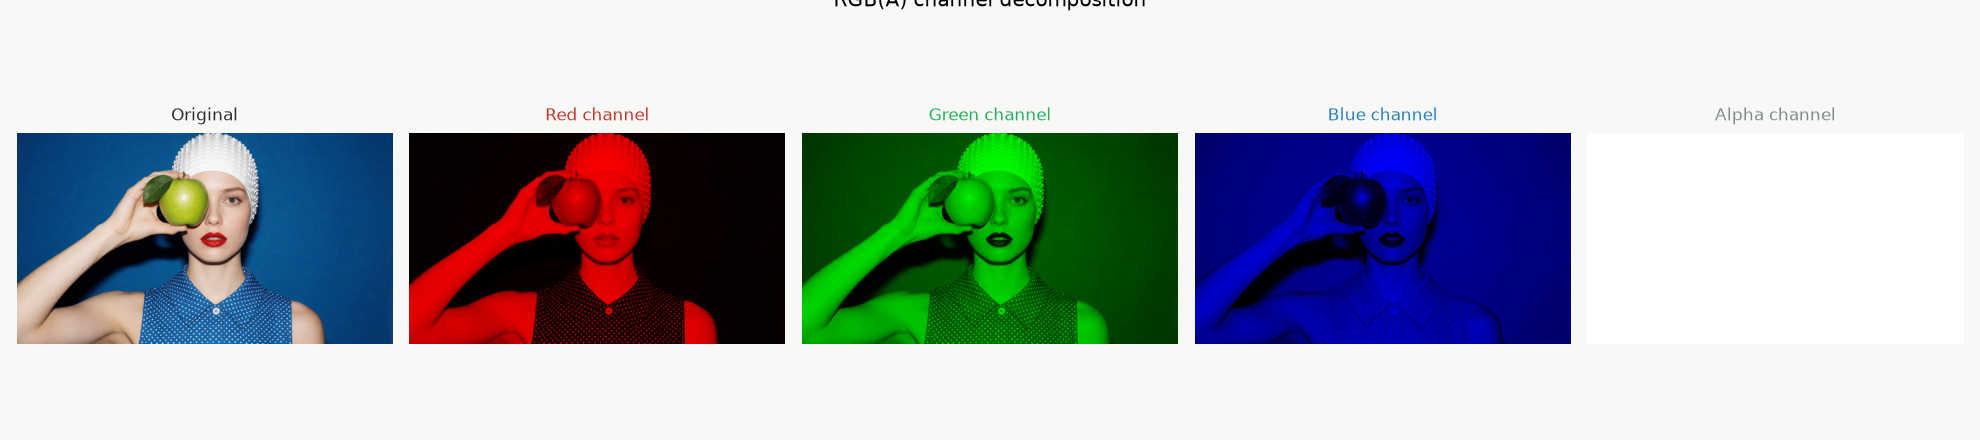


Channel averages:  R=70.6  G=104.3  B=133.6  A=255.0


In [20]:
R, G, B, A = arr[:,:,0], arr[:,:,1], arr[:,:,2], arr[:,:,3]

# Coloured channel images (each channel shown in its own colour)
ch_red   = np.stack([R, np.zeros_like(R), np.zeros_like(R)], axis=2).astype(np.uint8)
ch_green = np.stack([np.zeros_like(G), G, np.zeros_like(G)], axis=2).astype(np.uint8)
ch_blue  = np.stack([np.zeros_like(B), np.zeros_like(B), B], axis=2).astype(np.uint8)
ch_alpha = np.stack([A, A, A], axis=2).astype(np.uint8)  # grayscale

fig, axes = plt.subplots(1, 5, figsize=(18, 4))
fig.patch.set_facecolor('#f8f8f6')

panels = [
    (arr3,       'Original',       None),
    (ch_red,     'Red channel',    '#c0392b'),
    (ch_green,   'Green channel',  '#27ae60'),
    (ch_blue,    'Blue channel',   '#2980b9'),
    (ch_alpha,   'Alpha channel',  '#7f8c8d'),
]

for ax, (img_data, title, color) in zip(axes, panels):
    ax.imshow(img_data)
    ax.set_title(title, color=color if color else '#2c2c2a', fontweight='500')
    ax.axis('off')
    if color:
        for spine in ax.spines.values():
            spine.set_edgecolor(color)
            spine.set_linewidth(2)
            spine.set_visible(True)

fig.suptitle('RGB(A) channel decomposition', fontsize=13, fontweight='500', y=1.02)
plt.tight_layout()
plt.show()
print(f'\nChannel averages:  R={R.mean():.1f}  G={G.mean():.1f}  B={B.mean():.1f}  A={A.mean():.1f}')

---
## 4 — Greyscale channel views

Each channel shown as a **greyscale heatmap** — brighter = higher value.  
This makes it easier to see *where* each colour is intense in the image.

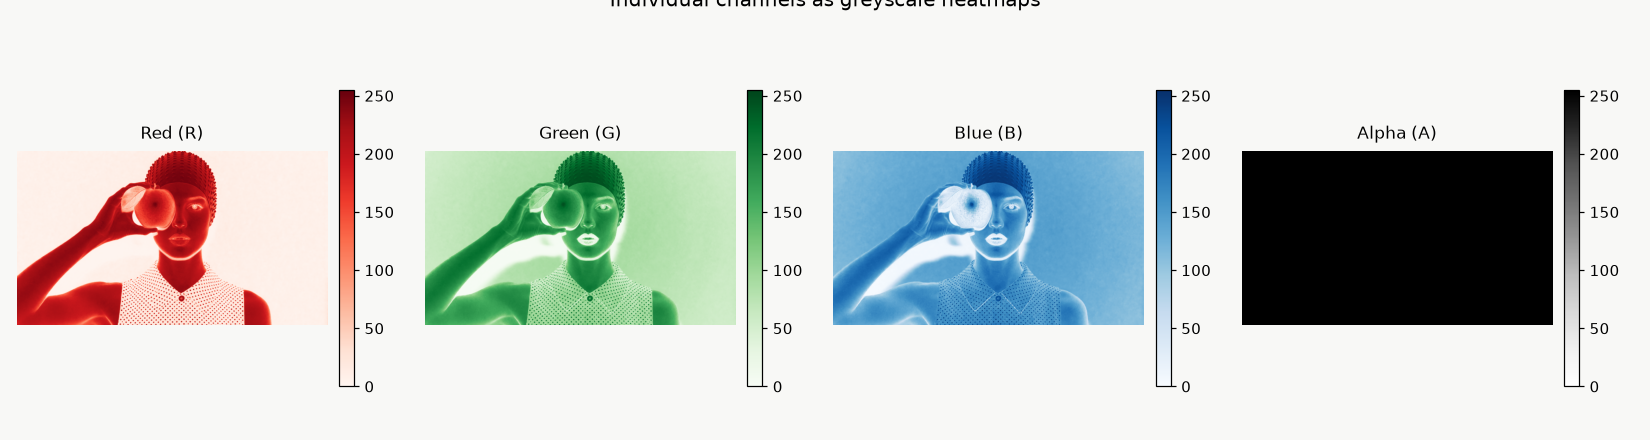

In [21]:
fig, axes = plt.subplots(1, 4, figsize=(15, 4))
fig.patch.set_facecolor('#f8f8f6')

channels = [
    (R, 'Reds',   'Red (R)'),
    (G, 'Greens', 'Green (G)'),
    (B, 'Blues',  'Blue (B)'),
    (A, 'Greys',  'Alpha (A)'),
]

for ax, (ch, cmap, label) in zip(axes, channels):
    im = ax.imshow(ch, cmap=cmap, vmin=0, vmax=255)
    ax.set_title(label, fontweight='500')
    ax.axis('off')
    plt.colorbar(im, ax=ax, shrink=0.8, pad=0.03)

fig.suptitle('Individual channels as greyscale heatmaps', fontsize=13, fontweight='500', y=1.02)
plt.tight_layout()
plt.show()

---
## 5 — Pixel value histograms

A histogram shows how pixel values are **distributed** across the image.  
- Peaks at 0 = lots of dark pixels in that channel  
- Peaks at 255 = lots of bright/saturated pixels  
- Spread across the range = good tonal range

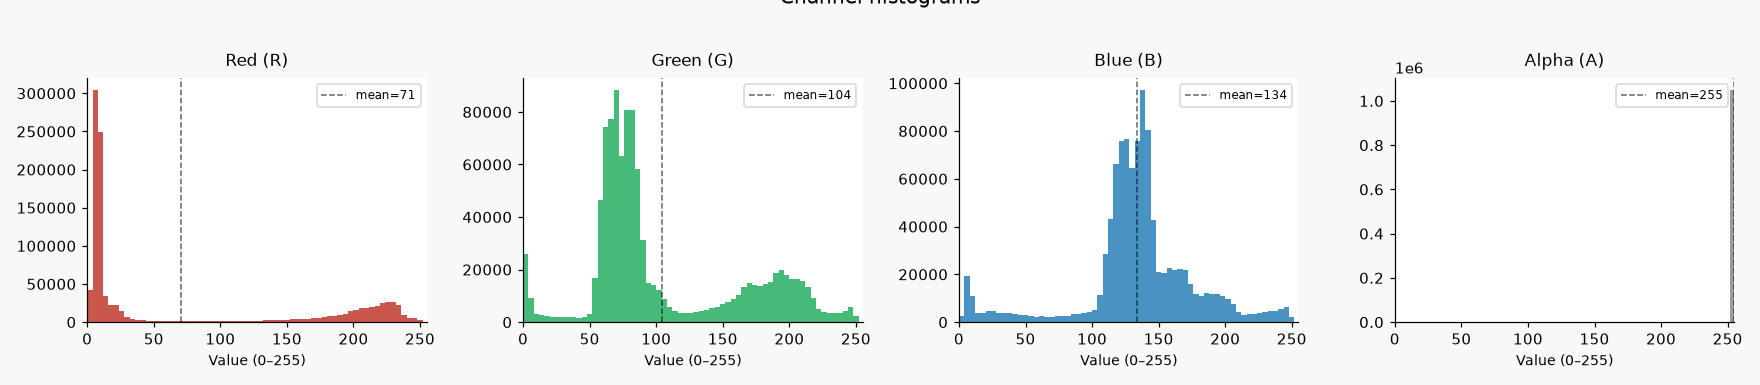

In [22]:
fig, axes = plt.subplots(1, 4, figsize=(16, 3.5), sharey=False)
fig.patch.set_facecolor('#f8f8f6')

ch_info = [
    (R, '#c0392b', 'Red (R)'),
    (G, '#27ae60', 'Green (G)'),
    (B, '#2980b9', 'Blue (B)'),
    (A, '#7f8c8d', 'Alpha (A)'),
]

for ax, (ch, color, label) in zip(axes, ch_info):
    ax.hist(ch.flatten(), bins=64, range=(0, 256), color=color, alpha=0.85, edgecolor='none')
    ax.axvline(ch.mean(), color='black', linewidth=1, linestyle='--', alpha=0.6, label=f'mean={ch.mean():.0f}')
    ax.set_title(label, fontweight='500')
    ax.set_xlabel('Value (0–255)', fontsize=9)
    ax.set_xlim(0, 255)
    ax.legend(fontsize=8)
    ax.spines[['top','right']].set_visible(False)

fig.suptitle('Channel histograms', fontsize=13, fontweight='500', y=1.03)
plt.tight_layout()
plt.show()

---
## 6 — Interactive pixel inspector

Use the sliders to pick any pixel coordinate and see its exact R/G/B/A values.

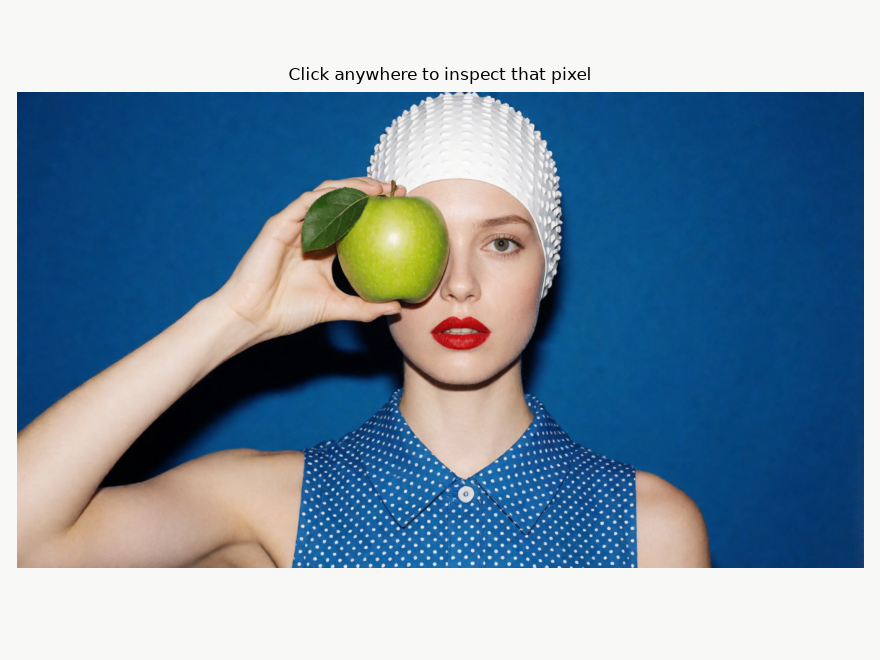

Output()

In [23]:
out = widgets.Output()

def show_inspector(x, y):
    with out:
        clear_output(wait=True)
        r_val, g_val, b_val, a_val = (int(v) for v in arr[y, x])
        hex_col = f'#{r_val:02X}{g_val:02X}{b_val:02X}'

        fig, axes = plt.subplots(1, 3, figsize=(12, 3.2),
                                  gridspec_kw={'width_ratios': [2.5, 2, 1.5]})
        fig.patch.set_facecolor('#f8f8f6')

        # Panel 1: image with crosshair
        axes[0].imshow(arr3)
        axes[0].axhline(y, color='white', linewidth=0.8, alpha=0.7)
        axes[0].axvline(x, color='white', linewidth=0.8, alpha=0.7)
        axes[0].plot(x, y, 'o', color='white', markersize=6, markeredgecolor='black', markeredgewidth=0.8)
        axes[0].set_title(f'Pixel [{x}, {y}]', fontweight='500')
        axes[0].axis('off')

        # Panel 2: bar chart
        channels_vals = [r_val, g_val, b_val, a_val]
        colors_bar    = ['#c0392b', '#27ae60', '#2980b9', '#7f8c8d']
        labels_bar    = ['R', 'G', 'B', 'A']
        bars = axes[1].barh(labels_bar, channels_vals, color=colors_bar, alpha=0.85)
        axes[1].set_xlim(0, 260)
        axes[1].set_xlabel('Value (0–255)', fontsize=9)
        axes[1].set_title('Channel values', fontweight='500')
        axes[1].spines[['top','right']].set_visible(False)
        for bar, val in zip(bars, channels_vals):
            axes[1].text(val + 4, bar.get_y() + bar.get_height()/2,
                         str(val), va='center', fontsize=10, fontweight='500')

        # Panel 3: colour swatch
        swatch = np.full((100, 100, 3), [r_val, g_val, b_val], dtype=np.uint8)
        axes[2].imshow(swatch)
        axes[2].set_title(hex_col, fontweight='500', fontfamily='monospace', fontsize=11)
        axes[2].axis('off')

        fig.suptitle(
            f'  R={r_val}  G={g_val}  B={b_val}  A={a_val}   |   Binary: {r_val:08b} / {g_val:08b} / {b_val:08b}',
            fontsize=9, fontfamily='monospace', y=0, color='#555'
        )
        plt.tight_layout()
        plt.show()

# --- clickable preview image ---
fig_pick, ax_pick = plt.subplots(figsize=(8, 6))
ax_pick.imshow(arr3)
ax_pick.set_title('Click anywhere to inspect that pixel', fontweight='500')
ax_pick.axis('off')
fig_pick.patch.set_facecolor('#f8f8f6')
plt.tight_layout()

def on_click(event):
    if event.inaxes is ax_pick and event.xdata is not None:
        x = int(np.clip(round(event.xdata), 0, W - 1))
        y = int(np.clip(round(event.ydata), 0, H - 1))
        show_inspector(x, y)

fig_pick.canvas.mpl_connect('button_press_event', on_click)
plt.show()

display(out)
show_inspector(W//2, H//2)  # initial render

---
## 7 — Zoom into the pixel grid

Zoom into a small region to *see the individual pixels* and their RGB values printed on each cell.

IntSlider(value=10, continuous_update=False, description='Zoom:', layout=Layout(width='400px'), max=20, min=4,…

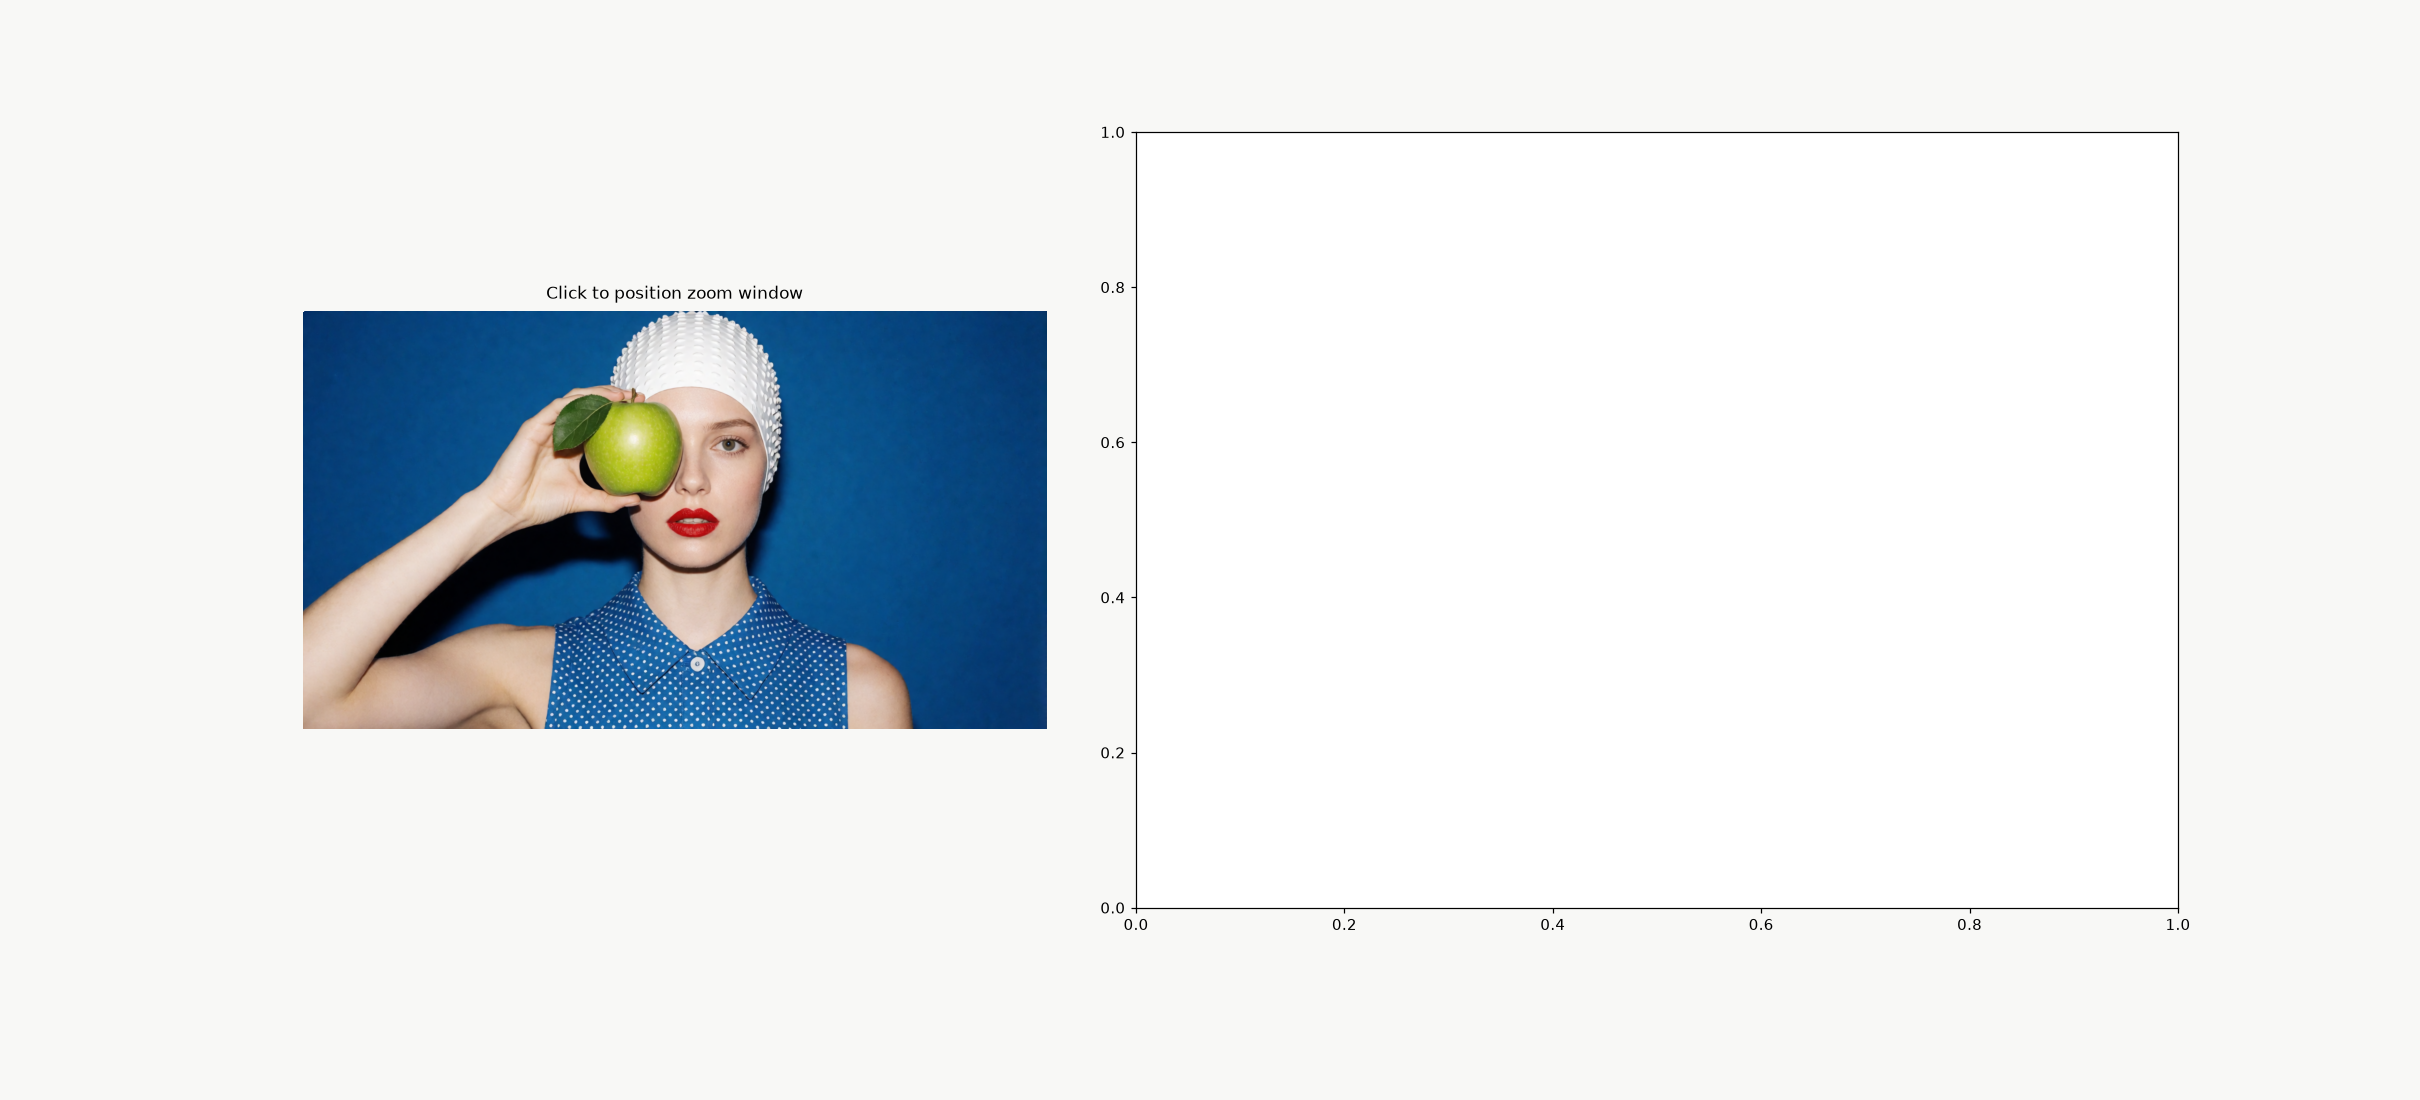

In [24]:
plt.close('all')
plt.ioff()

from matplotlib.patches import Rectangle

ZOOM_INIT = 10
center = [W // 2, H // 2]

fig = plt.figure(figsize=(22, 10))
fig.patch.set_facecolor('#f8f8f6')

# 3 rows: [image+label, coord text, grid] — use gridspec for fine control
gs = fig.add_gridspec(2, 2, width_ratios=[1, 1.4], height_ratios=[20, 1], hspace=0.08, wspace=0.1)
ax_ov    = fig.add_subplot(gs[0, 0])
ax_coord = fig.add_subplot(gs[1, 0])
ax_grid  = fig.add_subplot(gs[0, 1])
fig.add_subplot(gs[1, 1]).set_visible(False)  # spacer

ax_ov.imshow(arr3)
ax_ov.set_title('Click to position zoom window', fontweight='500')
ax_ov.axis('off')

ax_coord.axis('off')
coord_text = ax_coord.text(0.5, 0.5, '', ha='center', va='center',
                            fontsize=10, fontfamily='monospace',
                            transform=ax_coord.transAxes, color='#555')

zoom_rect = Rectangle((0, 0), 1, 1, linewidth=1.5, edgecolor='white', facecolor='none')
zoom_dot, = ax_ov.plot([], [], 'o', color='white', markersize=5,
                        markeredgecolor='black', markeredgewidth=0.8)
ax_ov.add_patch(zoom_rect)

zoom_slider = widgets.IntSlider(value=ZOOM_INIT, min=4, max=20, step=2,
                                description='Zoom:', continuous_update=False,
                                layout=widgets.Layout(width='400px'))

def update_overlay(cx, cy, zoom):
    x0 = max(0, cx - zoom//2); x1 = min(W, x0 + zoom)
    y0 = max(0, cy - zoom//2); y1 = min(H, y0 + zoom)
    zoom_rect.set_bounds(x0 - 0.5, y0 - 0.5, x1 - x0, y1 - y0)
    zoom_dot.set_data([cx], [cy])
    r_v, g_v, b_v = (int(v) for v in arr3[cy, cx])
    coord_text.set_text(f'x={cx}  y={cy}    R={r_v}  G={g_v}  B={b_v}    #{r_v:02X}{g_v:02X}{b_v:02X}')

def draw_grid(cx, cy, zoom):
    x0 = max(0, cx - zoom//2); x1 = min(W, x0 + zoom)
    y0 = max(0, cy - zoom//2); y1 = min(H, y0 + zoom)
    patch = arr3[y0:y1, x0:x1]
    ph, pw = patch.shape[:2]

    ax_grid.cla()
    ax_grid.imshow(patch, interpolation='nearest', aspect='equal')
    for row in range(ph):
        for col in range(pw):
            r_v, g_v, b_v = (int(v) for v in patch[row, col])
            lum = 0.299*r_v + 0.587*g_v + 0.114*b_v
            ax_grid.text(col, row, f'{r_v}\n{g_v}\n{b_v}',
                         ha='center', va='center', fontsize=6,
                         color='white' if lum < 128 else 'black',
                         fontfamily='monospace', linespacing=1.3)
    for i in range(pw + 1):
        ax_grid.axvline(i - 0.5, color='white', linewidth=0.5, alpha=0.5)
    for i in range(ph + 1):
        ax_grid.axhline(i - 0.5, color='white', linewidth=0.5, alpha=0.5)
    ax_grid.set_xticks(range(pw))
    ax_grid.set_yticks(range(ph))
    ax_grid.set_xticklabels([f'x={x0+i}' for i in range(pw)], fontsize=7, rotation=45, ha='right')
    ax_grid.set_yticklabels([f'y={y0+i}' for i in range(ph)], fontsize=7)
    ax_grid.set_title(f'{pw}×{ph} pixel grid (centred at [{cx},{cy}])  —  R / G / B per cell',
                      fontweight='500', pad=12)

def refresh(cx, cy, zoom):
    update_overlay(cx, cy, zoom)
    draw_grid(cx, cy, zoom)
    fig.canvas.draw_idle()

def on_click(event):
    if event.inaxes is ax_ov and event.xdata is not None:
        center[0] = int(np.clip(round(event.xdata), 0, W - 1))
        center[1] = int(np.clip(round(event.ydata), 0, H - 1))
        refresh(center[0], center[1], zoom_slider.value)

def on_zoom(change):
    refresh(center[0], center[1], change['new'])

fig.canvas.mpl_connect('button_press_event', on_click)
zoom_slider.observe(on_zoom, names='value')

display(zoom_slider)
display(fig.canvas)
refresh(center[0], center[1], zoom_slider.value)